# 3. A shared loading bay

**What you will learn**

- how to bargain when only a **few isolated agreements** are possible (no continuous price);
- the **discrete version of KS**, and the link between bargaining solutions and **social welfare** (sum, minimum, product);
- why the symmetry axiom can be **impossible** to satisfy with isolated agreements, and how **lotteries** (here: alternating days) fix it.


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bargain import *


## 3.1 The situation

In a pedestrian city centre, two delivery companies share **one loading bay**, open from 7h to 10h, in three slots of one hour.  
Each slot goes to one company.

| Slot | value for GreenVan (agent 1) | value for CityCargo (agent 2) |
|---|---|---|
| 7h | 5 | 4 |
| 8h | 3 | 3 |
| 9h | 1 | 2 |

GreenVan delivers fresh food: early slots matter a lot to it. CityCargo is more flexible.  
Without agreement, both double-park in the street (fines, delays, angry residents): each one gets 2, so $d = (2, 2)$ (`BAY_D=(2, 2)`).

`allocations()` lists the $2^3 = 8$ ways to give the slots, with the utilities.

In [22]:
table = allocations()
table

,company 1 gets,u1,u2
0,7h+8h+9h,9,0
1,7h+8h,8,2
2,7h+9h,6,3
3,7h,5,5
4,8h+9h,4,4
5,8h,3,6
6,9h,1,7
7,-,0,9


---
**Exercise 1** .  
Keep only the allocations that both companies prefer to the street (`acceptable`) and that are Pareto-optimal (`pareto`).  
Draw all the allocations with `plot_problem(points, d=BAY_D, labels=...)`.

In [ ]:
# Exercise 1: your code here
#use the acceptable function seen in BOOK 1

acceptable and Pareto-optimal:
 [[8. 2.]
 [6. 3.]
 [5. 5.]
 [3. 6.]]


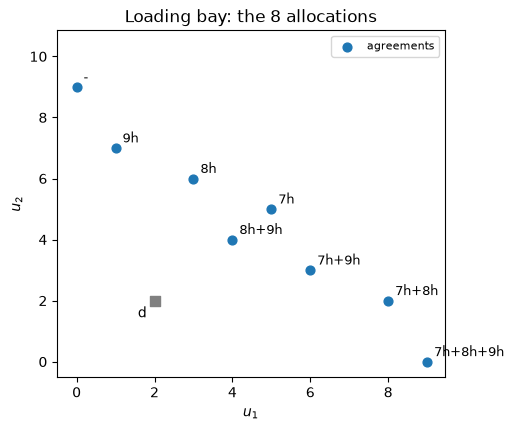

In [ ]:

plot_problem(points, d=BAY_D, labels=table["company 1 gets"], title="Loading bay: the 8 allocations");

**Reading.**  
Four allocations remain: $(8,2)$, $(6,3)$, $(5,5)$ and $(3,6)$.  
"Everything to one company" is refused by the other (it would rather go back to the street),  
and $(4,4)$ is dominated by $(5,5)$.

---


## 3.2 Four ways to choose

We try to compare four criteria, all computed on the gains:

| Criterion | choose the agreement that maximises |
|---|---|
| utilitarian | the sum $u_1 + u_2$ (total welfare) |
| egalitarian (Rawls) | the smallest gain $\min(u_1 - d_1,\ u_2 - d_2)$ |
| Nash | the product $(u_1 - d_1)(u_2 - d_2)$ (*Nash social welfare*) |
| KS (discrete) | the smallest share of one's best hope $\min_i \frac{u_i - d_i}{a_i - d_i}$ |

**Exercise 2**.   
For the acceptable allocations, *add four columns to a table*:  sum, smallest gain, Nash product, smallest KS share.  
Which allocation does each criterion choose? Are there ties?

In [ ]:
# ideal_point(points, d=(d1, d2)) return the ideal point (u1_max, u2_max) for the two companies, given the points and the disagreement point d
# the point that maximizes the gains for each company, and where utility company 1 = > d1 and utility company 2 = u2 - d2

In [8]:
#in pandas, 
# to filter a dataframe df by a condition on a column, you can use df[df['column_name'] > value]
# example lines where u1 >= 5
table[(table.u1 >= 5)]

,company 1 gets,u1,u2
0,7h+8h+9h,9,0
1,7h+8h,8,2
2,7h+9h,6,3
3,7h,5,5


In [11]:
#in panda, you can filter on more than one criterion 
# example lines where u1 >= 5 and u2 >= 5
table[(table.u1 >= 5) & (table.u2 >= 5)]

,company 1 gets,u1,u2
3,7h,5,5


In [ ]:
# Exercise 2: your code here


ideal point a = [8. 6.]


,company 1 gets,u1,u2,sum,min gain,Nash product,KS min share
1,7h+8h,8,2,10,0,0,0.00
2,7h+9h,6,3,9,1,4,0.25
3,7h,5,5,10,3,9,0.50
4,8h+9h,4,4,8,2,4,0.33
5,8h,3,6,9,1,4,0.17


**Reading.** Egalitarian, Nash and KS choose the same allocation: GreenVan takes the 7h slot, CityCargo the 8h and 9h slots, $(5, 5)$. The utilitarian criterion hesitates: $(8, 2)$ has the same total (10) but gives CityCargo nothing more than the street. The sum ignores **how** the welfare is shared.

---

## 3.3 Find a agreement

**Exercise 3** *(≈ 4 lines)*.  
Apply `utilitarian`, `egalitarian`, `nash_solution` and `ks_solution` to these points.  
Do you find the choices of the slide *Link with social welfare*?

In [16]:
# in bargain library : 
# MODULE1 is the table of the 8 allocations for the loading bay problem
MODULE1

,name,u1,u2
0,A,1,6.0
1,B,1,4.0
2,C,7,1.0
3,D,2,1.0
4,E,2,2.0
5,F,4,2.5


In [17]:
# in bargain library : 
# utilitarian(points): return the point maximizing the sum u1 + u2 (first one in case of a tie).
# egalitarian(points, d): return the point maximizing the smallest gain min(u1 - d1, u2 - d2).
# nash_solution(points, d): return the point maximizing the Nash product (u1 - d1)(u2 - d2).
# ks_solution(points, d): return the point maximizing the smallest relative gain (u_i - d_i) / (a_i - d_i).


In [7]:
# Exercise 3: your code here

In [18]:

for name, rule in (("utilitarian", utilitarian), ("egalitarian", egalitarian), ("Nash", nash_solution), ("KS", ks_solution)):
    p = rule(P1)
    print(f"{name:12s} -> {MODULE1.name[(P1 == p).all(axis=1)].item()} {p}")

utilitarian  -> C [7. 1.]
egalitarian  -> F [4.  2.5]
Nash         -> F [4.  2.5]
KS           -> F [4.  2.5]


**Reading.** The utilitarian criterion chooses $C(7,1)$, very unequal; the three others choose the balanced $F(4, 2.5)$.

---

## 3.4 When symmetry is impossible

Suppose now that the two companies have **the same needs**: both value the slots 4, 3 and 2.

**Exercise 4**.   
Build the allocations with `allocations(VALUES_2, VALUES_2)`,   
compute the Nash products with $d = (2, 2)$, and look for the best ones.   
Is there an allocation with $u_1 = u_2$?

In [9]:
# Exercise 4: your code here

allocations with u1 = u2: 0


,company 1 gets,u1,u2,Nash product
3,7h,4,5,6
4,8h+9h,5,4,6
5,8h,3,6,4
2,7h+9h,6,3,4


**Reading.**   
The problem is perfectly symmetric, but two allocations tie: $(4, 5)$ (GreenVan gets 7h) and $(5, 4)$ (GreenVan gets 8h and 9h).  
Choosing one of them favours one company; and **no allocation gives the same utility to both**.   
The symmetry axiom cannot be satisfied: with isolated agreements, Nash's theorem does not apply (it assumes $S$ convex).

---

## 3.5 Alternating days

The companies meet every working day. They can **alternate**: one day $(4, 5)$, the next day $(5, 4)$. On average each one gets $4.5$: it is a lottery between two agreements, and it fills the segment between them. `with_lotteries(points)` adds all such mixtures $\lambda P + (1 - \lambda) Q$.

**Exercise 5**.   
Compute the Nash solution of the symmetric problem **with** lotteries.   
Then do the same for the original problem (`table`) and for the points of module 1.  
When do lotteries change the solution?

In [11]:
# Exercise 5: your code here

symmetric problem, with lotteries: [4.5 4.5]
original problem, with lotteries : [5. 5.]
module 1 points, with lotteries  : [4.09  3.425]


**Reading.**

- Symmetric problem: alternating gives $(4.5, 4.5)$, Nash product $2.5^2 = 6.25 > 6$: better for both **and** symmetric.
- Original problem: nothing changes, $(5, 5)$ was already the best.
- Module 1 points: $F(4, 2.5)$ is below the segment $[A, C]$; with lotteries, the Nash solution becomes a mix of about 48 % $A$ and 52 % $C$, i.e. $(4.1, 3.4)$.

A lottery is an agreement **on a rule** ("one day each"), made before knowing who gets what.

## Key points

| Notion | In the loading bay |
|---|---|
| isolated agreements | 8 allocations of 3 slots; only 4 are acceptable and Pareto-optimal |
| social welfare | utilitarian (sum) may choose an unequal agreement; egalitarian, Nash and KS choose $(5,5)$ |
| discrete KS | maximise the smallest share of one's best hope |
| symmetry impossible | identical companies: two agreements tie, none is equal |
| lotteries | alternating days make $S$ convex and restore a symmetric solution |